# DINOv3 image feature extraction and matching

This notebook loads two images, extracts dense DINOv3 ViT patch descriptors, and finds mutual-nearest-neighbour matches. From the repository root, install the optional environment first:

```bash
python3 -m pip install -r requirements-dinov3.txt
```

This example uses the timm DINOv3 ViT-L checkpoint, matching Meta's reference dense-matching setup more closely than ViT-S. The checkpoint contains Meta's DINOv3 weights and license. If access requires it, authenticate with `hf auth login`; weights are downloaded and cached on the first run.

In [1]:
# Setup imports and make the repository module importable.
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "sample").is_dir():
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / "sample").is_dir():
    raise RuntimeError("Start Jupyter from the repository root or notebooks directory")
sys.path.insert(0, str(REPO_ROOT))

from sample.dinov3_feature_matching import (
    DINOv3FeatureExtractor,
    features_in_mask,
    filter_matches_with_fundamental_ransac,
    load_image,
    match_features,
    offset_feature_keypoints,
    plot_matches,
    score_image_match,
)

## 1. Read images from paths

The defaults use two repository images from `tests/data`. Replace either path to match another pair.

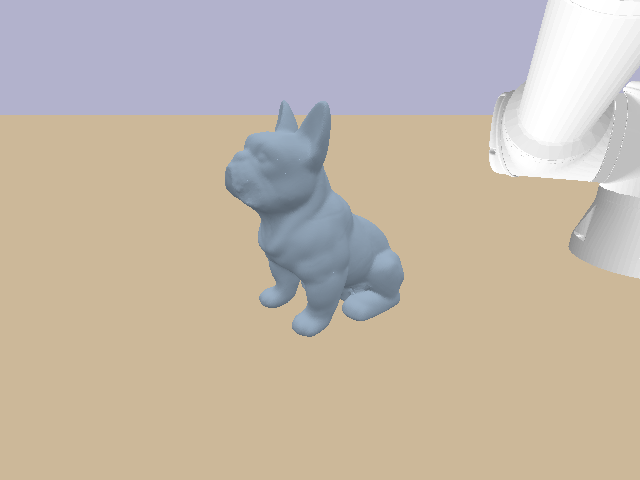

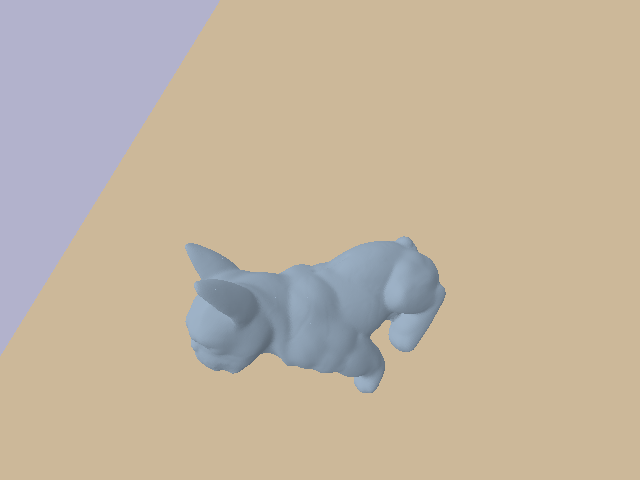

In [2]:
CURRENT_IMAGE_PATH = REPO_ROOT / "tests/data/side_1.png"
TARGET_IMAGE_PATH = REPO_ROOT / "tests/data/wrist_camera_latest_1785522986_target.png"

# Preserve RGB; grayscale makes the object and table less distinguishable.
image1 = load_image(CURRENT_IMAGE_PATH)
image2 = load_image(TARGET_IMAGE_PATH)

display(image1)
display(image2)

## 2. Run DINOv3 feature extraction

SAM first generates class-agnostic masks for everything in each RGB image. Scene-sized and boundary-connected masks are rejected; the remaining masks are ranked by segmentation quality and complete-object coverage. The selected target is cropped and upscaled for DINOv3. No class name, colour threshold, fixed position, fixed box, object size, or fixed image dimensions are used. The original SAM model is used because it supports the PyTorch 2.1.0a0 build in the CuRobo runtime.

In [3]:
import gc
from importlib.metadata import PackageNotFoundError, version as package_version

import torch

required_transformers = "4.44.2"
install_command = (
    f"{sys.executable} -m pip install -r "
    f"{REPO_ROOT / 'requirements-dinov3.txt'}"
)
try:
    installed_transformers = package_version("transformers")
except PackageNotFoundError:
    raise RuntimeError(
        "Transformers is not installed in this notebook kernel. Run "
        f"`{install_command}`, restart the kernel, and run all cells again."
    ) from None
if installed_transformers != required_transformers:
    raise RuntimeError(
        f"Transformers {installed_transformers} is incompatible with this CuRobo "
        f"PyTorch build. Install {required_transformers} with "
        f"`{install_command}`, restart the kernel, "
        "and run all cells again."
    )

from transformers import pipeline
from sample.dinov3_spatial_clustering import (
    plot_automatic_mask_proposal,
    select_automatic_object_mask,
)

SAM_MODEL_ID = "facebook/sam-vit-base"
DINO_MODEL_ID = "vit_large_patch16_dinov3.lvd1689m"
sam_device = 0 if torch.cuda.is_available() else -1
mask_generator = pipeline(
    task="mask-generation", model=SAM_MODEL_ID, device=sam_device
)
sam_output1 = mask_generator(image1, points_per_batch=32, pred_iou_thresh=0.88)
sam_output2 = mask_generator(image2, points_per_batch=32, pred_iou_thresh=0.88)
proposal1 = select_automatic_object_mask(
    sam_output1["masks"], sam_output1["scores"], (image1.height, image1.width)
)
proposal2 = select_automatic_object_mask(
    sam_output2["masks"], sam_output2["scores"], (image2.height, image2.width)
)
OBJECT_ROI_1 = proposal1.bbox_xyxy
OBJECT_ROI_2 = proposal2.bbox_xyxy
crop1 = image1.crop(OBJECT_ROI_1)
crop2 = image2.crop(OBJECT_ROI_2)
left1, top1, right1, bottom1 = OBJECT_ROI_1
left2, top2, right2, bottom2 = OBJECT_ROI_2
crop_mask1 = proposal1.mask[top1:bottom1, left1:right1].numpy()
crop_mask2 = proposal2.mask[top2:bottom2, left2:right2].numpy()

# Release SAM before loading DINOv3 so both large models do not occupy GPU memory.
del mask_generator, sam_output1, sam_output2
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

extractor = DINOv3FeatureExtractor(
    model_id=DINO_MODEL_ID, max_image_size=448, upscale_small_images=True
)
crop_features1 = extractor.extract(crop1, apply_background_filter=False)
crop_features2 = extractor.extract(crop2, apply_background_filter=False)
masked_features1 = features_in_mask(crop_features1, crop_mask1)
masked_features2 = features_in_mask(crop_features2, crop_mask2)
features1 = offset_feature_keypoints(
    masked_features1, OBJECT_ROI_1[:2], (image1.height, image1.width)
)
features2 = offset_feature_keypoints(
    masked_features2, OBJECT_ROI_2[:2], (image2.height, image2.width)
)

print(f"DINO model/device: {DINO_MODEL_ID} / {extractor.device}")
print(f"Automatic ROI 1:   {OBJECT_ROI_1}, score={proposal1.selection_score:.3f}")
print(f"Automatic ROI 2:   {OBJECT_ROI_2}, score={proposal2.selection_score:.3f}")
print(f"Current object: {len(features1.descriptors)} descriptors on grid {features1.grid_size}")
print(f"Target object:  {len(features2.descriptors)} descriptors on grid {features2.grid_size}")

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DINO model/device: vit_large_patch16_dinov3.lvd1689m / cuda
Automatic ROI 1:   (189, 65, 440, 372), score=0.775
Automatic ROI 2:   (146, 198, 484, 432), score=0.816
Current object: 192 descriptors on grid (28, 22)
Target object:  191 descriptors on grid (19, 28)


## 3. Run feature matching

Matching uses mutual nearest neighbours followed by fundamental-matrix RANSAC. At least 16 descriptor candidates are required: eight candidates are not a valid robustness test because an eight-point model can fit all eight. The final `[0, 1]` score fuses DINO descriptor similarity, geometric inlier consistency, and median local ZNCC around verified correspondences. Local ZNCC is used instead of whole-image ZNCC so object translation and different image dimensions do not invalidate the photometric term. Higher is better.

Descriptor candidates: 68
Geometric inliers:     57 (83.8%)
First five inlier scores: [0.8430675268173218, 0.839992344379425, 0.8384074568748474, 0.837176501750946, 0.8357908129692078]
Combined image-match score: 0.822 / 1.000
  DINO + geometry:           0.868
  mean DINO cosine:          0.797
  geometric inlier ratio:    83.8%
  median local ZNCC:         0.430
  valid ZNCC patches:        57


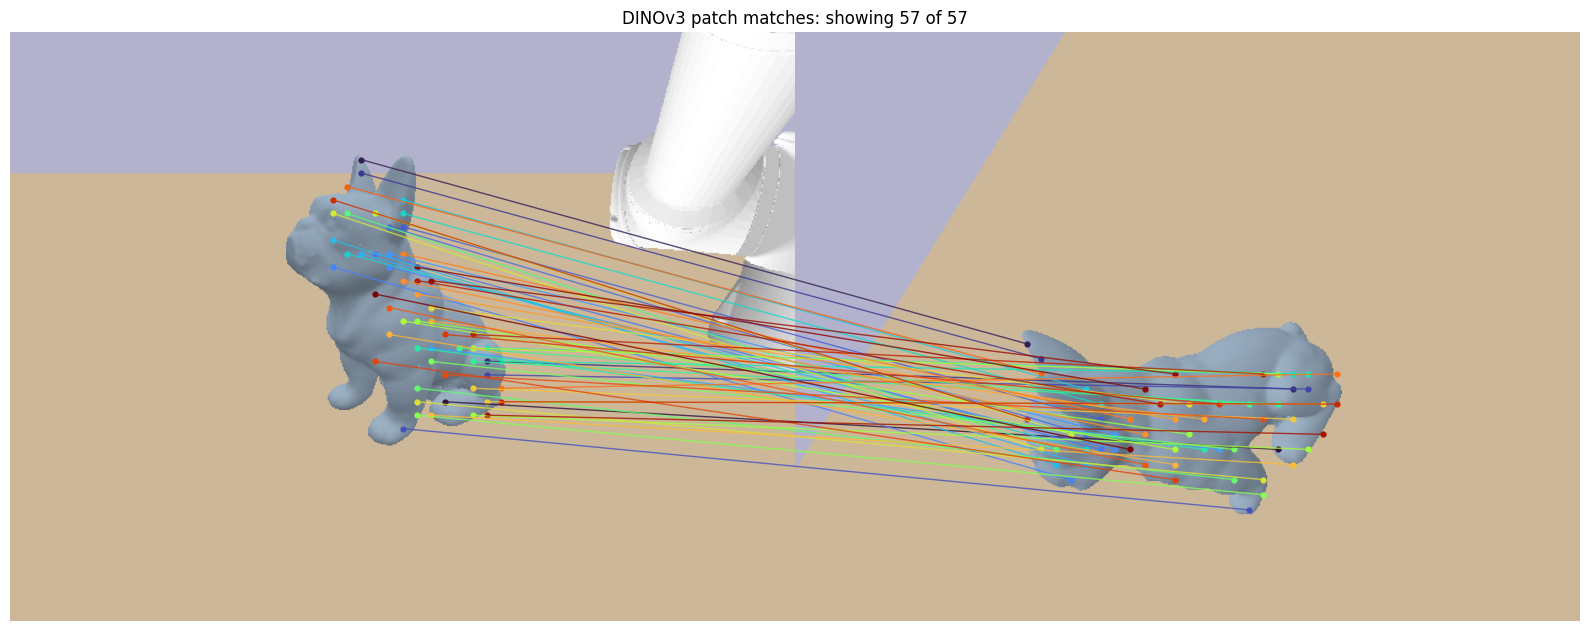

In [4]:
candidate_matches = match_features(
    features1,
    features2,
    similarity_threshold=0.60,
    min_similarity_margin=0.0,
    max_distance_ratio=None,
    max_matches=None,
)
if len(candidate_matches) < 16:
    raise RuntimeError(
        f"Only {len(candidate_matches)} candidates: refusing an under-constrained "
        "geometric result instead of displaying unreliable matches."
    )
matches = filter_matches_with_fundamental_ransac(
    candidate_matches,
    reprojection_threshold_px=6.0,
)
inlier_ratio = len(matches) / len(candidate_matches)
if len(matches) < 12 or inlier_ratio < 0.30:
    raise RuntimeError(
        f"Geometric verification is weak: {len(matches)} inliers "
        f"out of {len(candidate_matches)} ({inlier_ratio:.1%})."
    )
print(f"Descriptor candidates: {len(candidate_matches)}")
print(f"Geometric inliers:     {len(matches)} ({inlier_ratio:.1%})")
print("First five inlier scores:", matches.scores[:5].tolist())

match_score = score_image_match(image1, image2, candidate_matches, matches)
print(f"Combined image-match score: {match_score.score:.3f} / 1.000")
print(f"  DINO + geometry:           {match_score.feature_score:.3f}")
print(f"  mean DINO cosine:          {match_score.mean_descriptor_similarity:.3f}")
print(f"  geometric inlier ratio:    {match_score.geometric_inlier_ratio:.1%}")
print(f"  median local ZNCC:         {match_score.median_zncc:.3f}")
print(f"  valid ZNCC patches:        {match_score.zncc_patch_count}")

figure, axes = plot_matches(image1, image2, matches, max_display=100)

## 4. Inspect automatic object discovery

SAM runs in segment-everything mode using RGB only—no depth, simulator segmentation, category label, colour rule, or manual box. Automatic target selection assumes one salient object separated from the image boundary. Always inspect these masks before trusting correspondence results.

(<Figure size 1200x500 with 2 Axes>,
 array([<Axes: title={'center': 'Automatic object mask (SAM score 0.986)'}>,
        <Axes: title={'center': 'Automatic crop (selection score 0.816)'}>],
       dtype=object))

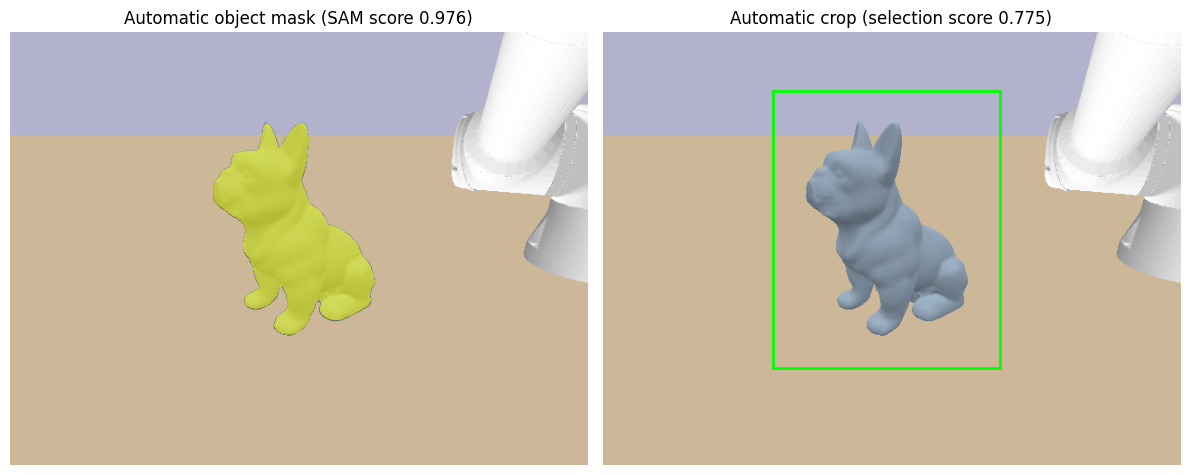

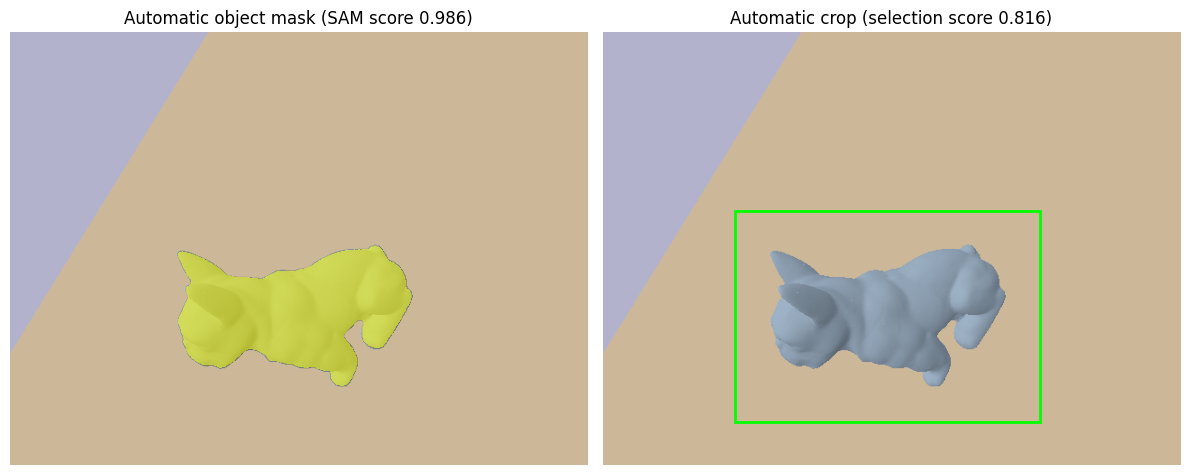

In [5]:
plot_automatic_mask_proposal(image1, proposal1)
plot_automatic_mask_proposal(image2, proposal2)

## 5. Verify coordinate mapping

These diagnostics expose automatically chosen crop sizes, independent resizing, and final coordinate mapping. Selected keypoints must map back inside their automatically inferred full-image boxes.

In [6]:
print("Current crop original/processed:", crop_features1.original_size, crop_features1.processed_size)
print("Target crop original/processed: ", crop_features2.original_size, crop_features2.processed_size)
print("Current full-image range:", features1.keypoints.amin(dim=0).tolist(), features1.keypoints.amax(dim=0).tolist())
print("Target full-image range: ", features2.keypoints.amin(dim=0).tolist(), features2.keypoints.amax(dim=0).tolist())

for features, (left, top, right, bottom) in (
    (features1, OBJECT_ROI_1), (features2, OBJECT_ROI_2)
):
    assert bool(((features.keypoints[:, 0] >= left) & (features.keypoints[:, 0] < right)).all())
    assert bool(((features.keypoints[:, 1] >= top) & (features.keypoints[:, 1] < bottom)).all())

Current crop original/processed: (307, 251) (448, 352)
Target crop original/processed:  (234, 338) (304, 448)
Current full-image range: [228.93182373046875, 103.375] [400.06817626953125, 333.625]
Target full-image range:  [188.25, 241.10525512695312] [441.75, 388.89471435546875]


## 6. Rank the latest four robot captures against the target

This block reads the newest complete capture manifest from `output/pybullet/four_views`, segments each robot RGB image, computes DINO correspondences and geometric inliers against the target from `tests/data`, then ranks all four views with the combined DINO–geometry–ZNCC score. Failed geometric comparisons are reported instead of receiving a misleading score.

Target: /workspace/tests/data/wrist_camera_latest_1785522986_target.png
Capture run: /workspace/output/pybullet/four_views/capture_manifest_20260731T203816_510905Z.json
side_1: score=0.808, DINO+geometry=0.867, ZNCC=0.340, inliers=56/67
   top: score=0.667, DINO+geometry=0.721, ZNCC=0.084, inliers=28/47
side_2: rejected (only 5 descriptor candidates)
side_3: rejected (only 0 descriptor candidates)

Best robot view: side_1 -> /workspace/output/pybullet/four_views/side_1_20260731T203843_947221Z.png
Highest combined score: 0.808 / 1.000
Saved comparison figure to: /workspace/output/pybullet/four_views/best_match_comparison.png


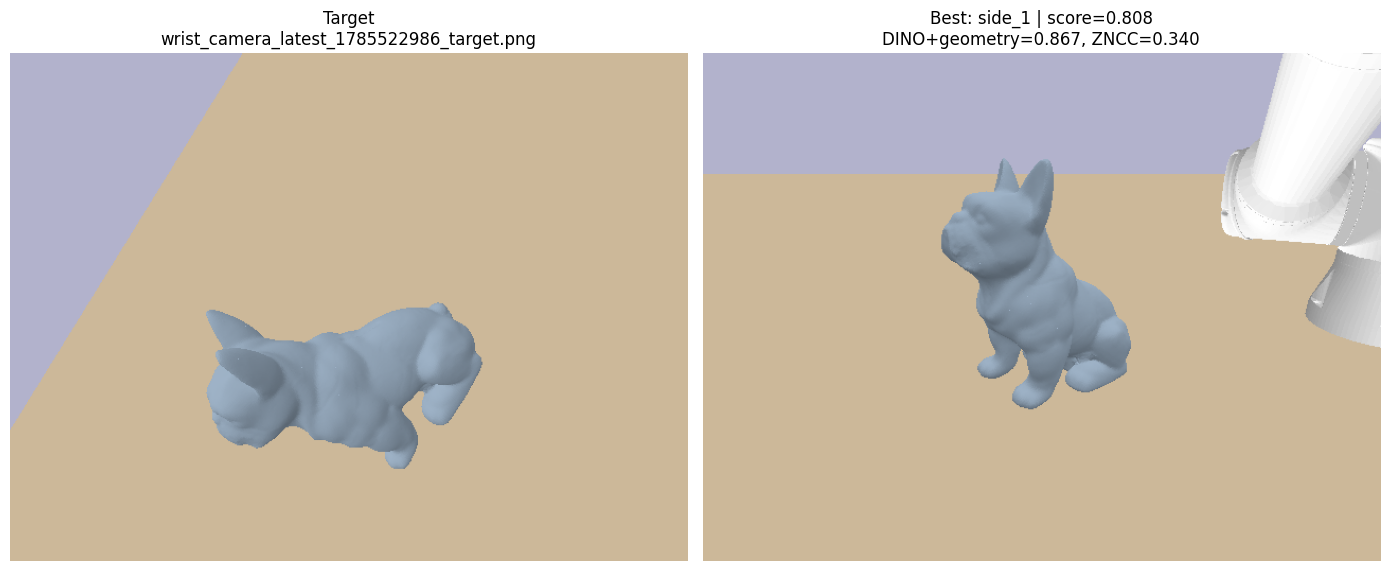

In [7]:
import json

import matplotlib.pyplot as plt

CAPTURE_DIR = REPO_ROOT / "output/pybullet/four_views"
EXPECTED_REGIONS = ("top", "side_1", "side_2", "side_3")
TEST_DATA_DIR = (REPO_ROOT / "tests/data").resolve()
ranking_target_path = TARGET_IMAGE_PATH.resolve()
if ranking_target_path.parent != TEST_DATA_DIR:
    raise RuntimeError(f"Target must come from {TEST_DATA_DIR}, got {ranking_target_path}")
ranking_target_image = load_image(ranking_target_path)


def latest_complete_capture_run(capture_dir):
    for manifest_path in reversed(sorted(capture_dir.glob("capture_manifest_*.json"))):
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        captures = manifest.get("captures", [])
        by_region = {capture.get("region"): capture for capture in captures}
        if manifest.get("status") != "complete":
            continue
        if set(by_region) != set(EXPECTED_REGIONS):
            continue
        image_paths = {
            region: capture_dir / by_region[region]["image_filename"]
            for region in EXPECTED_REGIONS
        }
        if all(path.is_file() for path in image_paths.values()):
            return manifest_path, manifest, image_paths
    raise FileNotFoundError(
        f"No complete four-image capture manifest was found in {capture_dir}"
    )


manifest_path, capture_manifest, robot_image_paths = latest_complete_capture_run(
    CAPTURE_DIR
)
robot_images = {region: load_image(path) for region, path in robot_image_paths.items()}
print(f"Target: {ranking_target_path}")
print(f"Capture run: {manifest_path}")

# Free GPU memory occupied by DINO while SAM segments all four images.
dino_device = extractor.device
extractor.model.to("cpu")
extractor.device = torch.device("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

robot_proposals = {}
mask_generator = pipeline(
    task="mask-generation",
    model=SAM_MODEL_ID,
    device=0 if torch.cuda.is_available() else -1,
)
try:
    for region in EXPECTED_REGIONS:
        image = robot_images[region]
        output = mask_generator(
            image, points_per_batch=32, pred_iou_thresh=0.88
        )
        robot_proposals[region] = select_automatic_object_mask(
            output["masks"], output["scores"], (image.height, image.width)
        )
finally:
    del mask_generator
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    extractor.model.to(dino_device)
    extractor.device = dino_device

ranking = []
for region in EXPECTED_REGIONS:
    image = robot_images[region]
    proposal = robot_proposals[region]
    left, top, right, bottom = proposal.bbox_xyxy
    crop = image.crop(proposal.bbox_xyxy)
    crop_mask = proposal.mask[top:bottom, left:right].numpy()
    try:
        crop_features = extractor.extract(crop, apply_background_filter=False)
        masked_features = features_in_mask(crop_features, crop_mask)
        robot_features = offset_feature_keypoints(
            masked_features, (left, top), (image.height, image.width)
        )
        candidates = match_features(
            robot_features,
            features2,
            similarity_threshold=0.60,
            min_similarity_margin=0.0,
            max_distance_ratio=None,
            max_matches=None,
        )
        if len(candidates) < 16:
            raise RuntimeError(f"only {len(candidates)} descriptor candidates")
        inliers = filter_matches_with_fundamental_ransac(
            candidates, reprojection_threshold_px=6.0
        )
        inlier_ratio = len(inliers) / len(candidates)
        if len(inliers) < 12 or inlier_ratio < 0.30:
            raise RuntimeError(
                f"weak geometry: {len(inliers)}/{len(candidates)} inliers"
            )
        result = score_image_match(
            image, ranking_target_image, candidates, inliers
        )
    except (ValueError, RuntimeError) as exc:
        ranking.append(
            {"region": region, "path": robot_image_paths[region], "error": str(exc)}
        )
    else:
        ranking.append(
            {
                "region": region,
                "path": robot_image_paths[region],
                "image": image,
                "score": result,
                "matches": inliers,
            }
        )

valid_ranking = sorted(
    (entry for entry in ranking if "score" in entry),
    key=lambda entry: entry["score"].score,
    reverse=True,
)
for entry in valid_ranking:
    result = entry["score"]
    print(
        f"{entry['region']:>6}: score={result.score:.3f}, "
        f"DINO+geometry={result.feature_score:.3f}, "
        f"ZNCC={result.median_zncc:.3f}, "
        f"inliers={result.inlier_count}/{result.candidate_count}"
    )
for entry in ranking:
    if "error" in entry:
        print(f"{entry['region']:>6}: rejected ({entry['error']})")
if not valid_ranking:
    raise RuntimeError("None of the four robot images passed geometric verification")

best_match = valid_ranking[0]
best_robot_image_path = best_match["path"]
best_robot_image = best_match["image"]
best_score = best_match["score"]
print(f"\nBest robot view: {best_match['region']} -> {best_robot_image_path}")
print(f"Highest combined score: {best_score.score:.3f} / 1.000")

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(ranking_target_image)
axes[0].set_title(f"Target\n{ranking_target_path.name}")
axes[1].imshow(best_robot_image)
axes[1].set_title(
    f"Best: {best_match['region']} | score={best_score.score:.3f}\n"
    f"DINO+geometry={best_score.feature_score:.3f}, ZNCC={best_score.median_zncc:.3f}"
)
for axis in axes:
    axis.axis("off")
figure.tight_layout()
comparison_path = CAPTURE_DIR / "best_match_comparison.png"
figure.savefig(comparison_path, dpi=160, bbox_inches="tight")
print(f"Saved comparison figure to: {comparison_path}")